<a href="https://colab.research.google.com/github/mf1060/ml-2026/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Michael Furey

Dr. Forouraghi

HW #4

October 19, 2026

The following is an analysis of the heart disease [dataset](https://archive.ics.uci.edu/dataset/45/heart+disease) with the machine learning repository at UC Irvine. This notebook uses methods from the [breast cancer notebook](https://github.com/bforoura/ML26/blob/main/Module5_SVM_DT/breast_cancer.ipynb). The goal of this assignment is to use support vector machines and decision trees to classify the chances of someone developing heart disease.

This notebook uses code and methods from the class [End-to-End Machine Learning Project](https://github.com/bforoura/ML26/blob/main/Module2_ML_Projects/02_end_to_end_machine_learning_project.ipynb) and makes reference to our textbook (Aurélien Géron, Hands-On Machine Learning with SciKit-Learn and PyTorch (2025)).

In [1]:
pip install ucimlrepo

# Task 1: Loading the dataset

This method uses the UCI library ("ucimlrepo") to read in the dataset.

In [2]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

from ucimlrepo import fetch_ucirepo

# # Loading the dataset from UCI: https://archive.ics.uci.edu/dataset/45/heart+disease
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
# Replacing ? with np.nan
# With reference to: https://www.geeksforgeeks.org/data-analysis/python-pandas-dataframe-replace/#google_vignette
X = heart_disease.data.features.replace("?", np.nan)
#Setting a variable for the original targets
#Replacing values of 2, 3, 4 with 1 in order to create a binary target variable
y = heart_disease.data.targets.replace(2, 1).replace(3, 1).replace(4, 1)

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)

# Split the data into training and testing sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")
print(f"Class distribution in y_train:\n{y_train.value_counts(normalize=True)}")

{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

# Task 2: Inspection Methods

We first use `.head()` `.info()` to view the first 5 rows of the feature and target dataframes. We see that all values have a numeric data type, either int or float. This means that there are no characters in this dataset.

In [3]:
# Display the first 5 rows
display(X.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(X.info())
display(X.describe())

# Display the first 5 rows
display(y.head())

# Print concise summary of columns, non-null counts, and data types
print("\nDataset Information:")
display(y.info())
display(y.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


None

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000


,num
0,0
1,1
2,1
3,0
4,0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   num     303 non-null    int64
dtypes: int64(1)
memory usage: 2.5 KB


None

,num
count,303.000000
mean,0.458746
std,0.499120
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


# Task 3: Assessing Missing Values

We can take a distribution to better understand how to impute missing values. We can see that many continuous features form a standard distribution. We can use a Standard imputer for these columns.


array([[<Axes: title={'center': 'age'}>, <Axes: title={'center': 'sex'}>,
        <Axes: title={'center': 'cp'}>,
        <Axes: title={'center': 'trestbps'}>],
       [<Axes: title={'center': 'chol'}>,
        <Axes: title={'center': 'fbs'}>,
        <Axes: title={'center': 'restecg'}>,
        <Axes: title={'center': 'thalach'}>],
       [<Axes: title={'center': 'exang'}>,
        <Axes: title={'center': 'oldpeak'}>,
        <Axes: title={'center': 'slope'}>,
        <Axes: title={'center': 'ca'}>],
       [<Axes: title={'center': 'thal'}>, <Axes: >, <Axes: >, <Axes: >]],
      dtype=object)

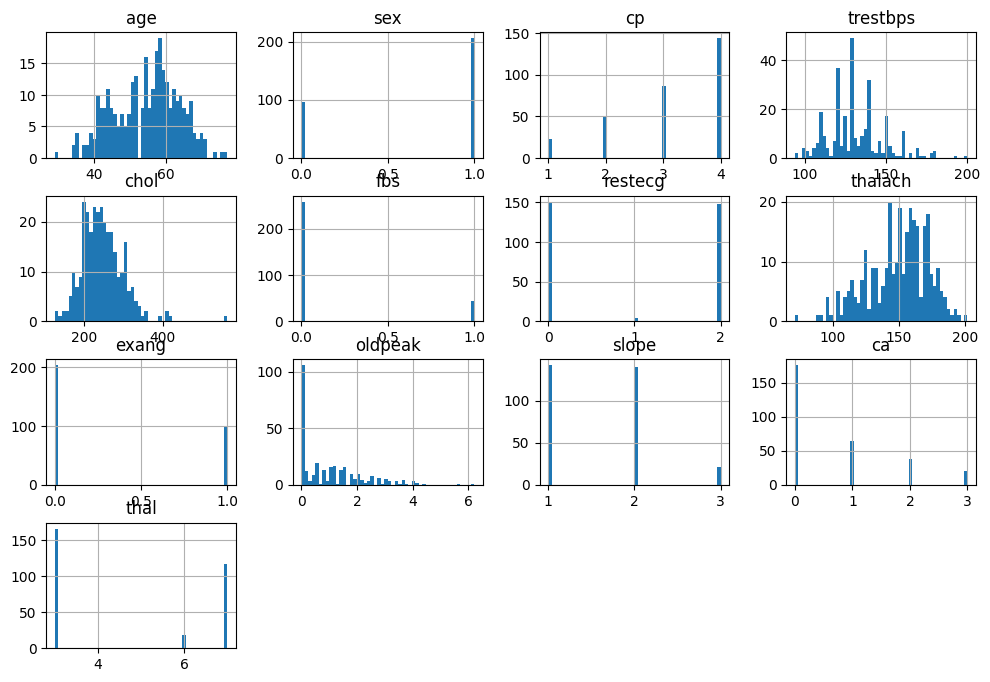

In [4]:
X.hist(bins=50, figsize=(12, 8))

# Task 4: Building Pipelines

With the following definitions, we use create pipelines for both numeric and categorical features to preprocess data and then define pipeline for Support Vector Classification (SVC), Decision Tree Classification, and a SVC classification that uses a grid search to identify the ideal parameters, c and gamma.

In [5]:
#Importing the method for a pipeline
from sklearn.pipeline import Pipeline
#Importing a simple imputer for filling empty values
from sklearn.impute import SimpleImputer
#Importing a one hot encoder for creating dummy variables for categorical data
from sklearn.preprocessing import OneHotEncoder
#Importing libraries for creating pipelines and a transformer
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
#Importing a Standard Scaler to standardize values.
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import make_column_selector, make_column_transformer

#Importing SGD Classifier
from sklearn.linear_model import SGDClassifier

#Importing SVC
from sklearn.svm import SVC

# Using methods from "end-to-end machine learning project"
from sklearn.preprocessing import FunctionTransformer

# Using https://archive.ics.uci.edu/dataset/45/heart+disease to identify
# numeric and categorical features
numeric_features = [
    'age','trestbps', 'chol', 'thalach', 'oldpeak'
]
categorical_features = ['sex', 'cp', 'fbs', 'restecg', 'slope', 'exang', 'ca', 'thal']

#Importing libraries for Decision Trees, cross validation scoring,
# and creating a classification report
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import classification_report

# The following defines the pipeline for numeric values that imputes
# a median value and a standard scaler.
numeric_transformer_standard = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# The following is a transformer that imputes values with their most
# frequent entry and one-hot encodes each of them.
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Defining a ColumnTransformer for transforming both numeric and
# categorical features.
preprocessor_standard = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer_standard, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Creating full pipeline for the svc classifier
svc = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    ('classifier', SVC(C=1.0, kernel='rbf', random_state=42, probability=True))

])

# Creating full pipeline for the decision tree classifier using the
# configuration from the breast cancer notebook.
dtc = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # Initialize the Decision Tree Classifier with regularization parameters to prevent overfitting
    ('classifier', DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, random_state=42))
])

# GridSearch pipeline
from sklearn.model_selection import GridSearchCV

#With reference to parameters from pg. 153 of the Texbook,
# the following uses various parameters for C and gamma for the grid search.
params = {
    'C': [0.001, 0.01, 0.1, 0, 1, 10, 100, 1000],
    'gamma': [0.1, 0, 1, 2, 3, 4, 5]
}
# Using documentation from: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
# creating a pipeline that uses grid search to find ideal parameters for C and gamma.
grid = Pipeline(steps=[
    ('preprocessor', preprocessor_standard),
    # With reference to pages 152-153 of the textbook,
    # implementing the svc with grid search
    ('classifier', GridSearchCV(
        SVC(kernel='rbf', random_state=42, probability=True), param_grid=params))
])

print("Pipelines constructed successfully.")

Pipelines constructed successfully.


# Results

The following defines a function that displays a confusion matrix, classification report and ROC-AUC curve for Tasks 5 and 6. This function uses code and methods from the [Spam, No Spam Classification Notebook](https://github.com/bforoura/ML26/blob/main/Module3_Classification/spam_nospam_sgdclassifier.ipynb) including its documentation.

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
import pandas as pd
from sklearn.model_selection import train_test_split

def results(test_size_var, pipeline):
  # Split data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size_var, random_state=42)

  # Fit the model on the full training data
  pipeline.fit(X_train, y_train)

  # Generate predictions for training and testing sets
  y_pred = pipeline.predict(X_test)
  y_scores = pipeline.predict_proba(X_test)[:,1]

  #Using the Pipeline documentation for get_params:https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

  # Print classification report
  print("Classification Report:")
  print(classification_report(y_test, y_pred))

  # Plot Confusion Matrix
  fig, ax = plt.subplots(figsize=(6, 6))
  ConfusionMatrixDisplay.from_estimator(pipeline, X_test, y_test, ax=ax, cmap='Blues', values_format='d')
  plt.title('Confusion Matrix')
  plt.show()

  # Compute ROC Curve and ROC-AUC
  fpr, tpr, thresholds = roc_curve(y_test, y_scores)
  roc_auc = auc(fpr, tpr)

  # Plot ROC Curve
  plt.figure(figsize=(6, 6))
  plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
  plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
  plt.xlim([0.0, 1.0])
  plt.ylim([0.0, 1.05])
  plt.xlabel('False Positive Rate')
  plt.ylabel('True Positive Rate')
  plt.title('Receiver Operating Characteristic (ROC) Curve')
  plt.legend(loc="lower right")
  plt.show()

  # Extract feature names from the preprocessor step
  cat_encoder = pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
  encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

  # Combine numerical and encoded categorical feature names
  all_feature_names = numeric_features + encoded_cat_features

# Task 5: SVC

Using a support vector classifier, we can see that it creates a strong classification model with an AUC = 0.93.

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.90      0.88        29
           1       0.90      0.88      0.89        32

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


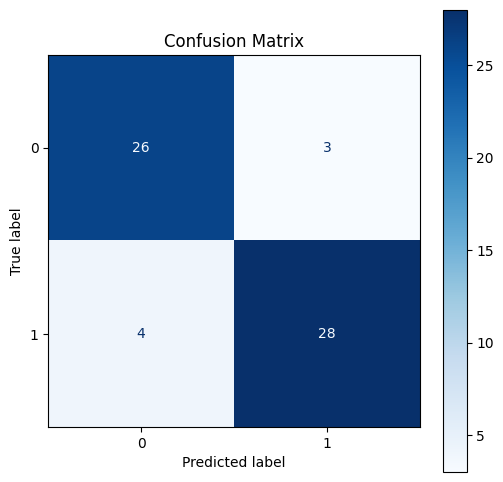

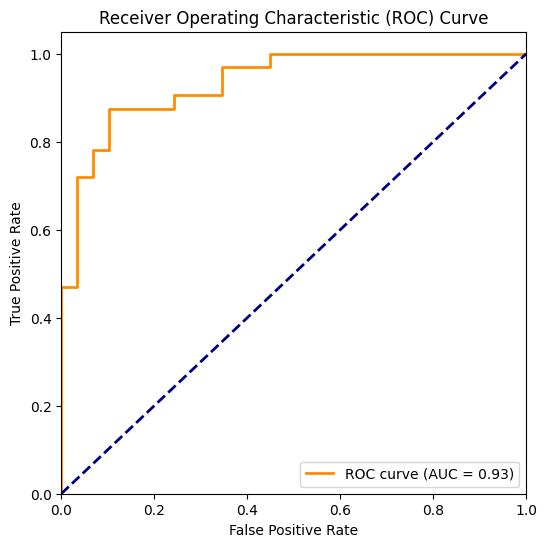

In [7]:
results(0.2, svc)

# Task 6: Decision Tree

The following uses a decision tree classification. We see that it performs less effectively than the SVC classifier with an AUC score of 0.83.

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.90      0.78        29
           1       0.87      0.62      0.73        32

    accuracy                           0.75        61
   macro avg       0.78      0.76      0.75        61
weighted avg       0.78      0.75      0.75        61



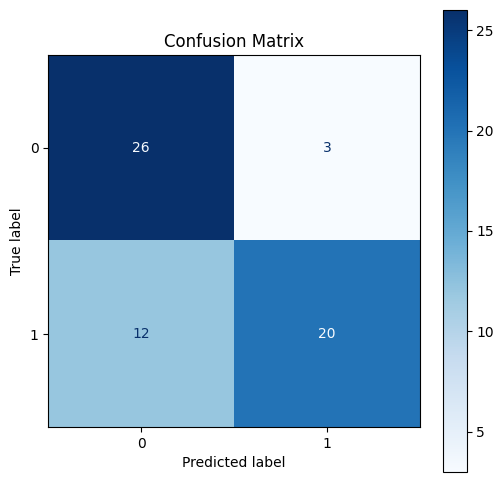

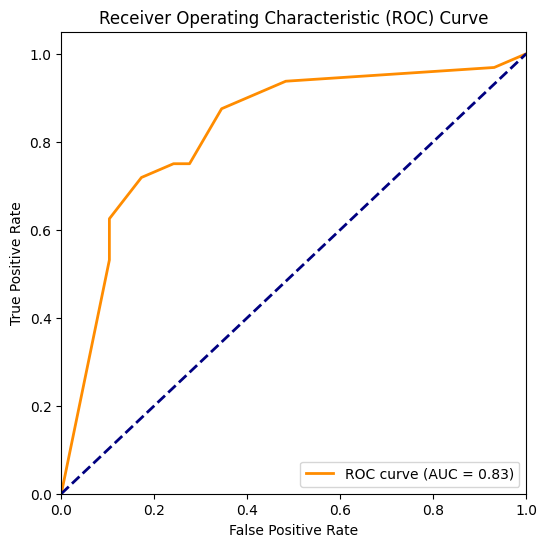

In [8]:
results(0.2, dtc)

# Task 7: GridSearchCV

The following reports results of a GridSearch that uses ideal parameters for the support vector classifier. We can see that this results in a model with an AUC score of 0.93, the same as the SVC classifier above.  

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for exam

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.86      0.86        29
           1       0.88      0.88      0.88        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



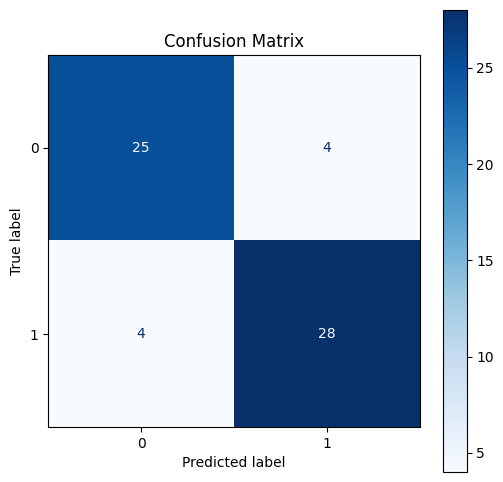

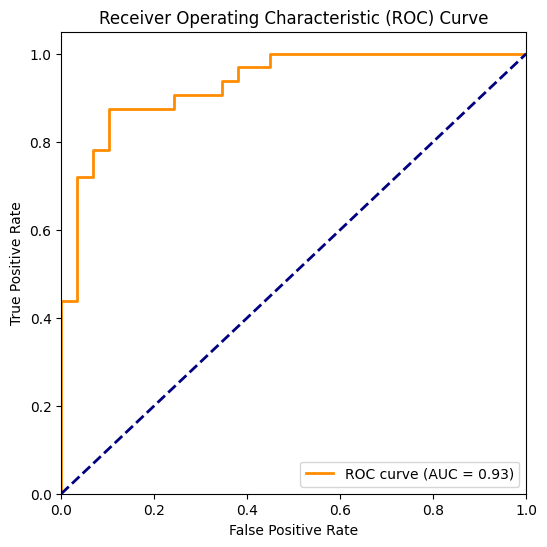

In [9]:
results(0.2, grid)

Here we can print out the configurations for the best estimator. The GridSearch used a C of 1 and a gamma of 0.1.

In [10]:
print(grid.named_steps['classifier'].best_estimator_)

SVC(C=1, gamma=0.1, probability=True, random_state=42)


# **Task 8: Visualizing the Decision Tree**


The following uses a plot to visualize the decision tree fitted in the previous model. One can see that the first division is drawn at chest pain. If there is non-asymptomatic chest pain, the decision tree separates roughly half of values for a higher chance of heart disease. Those who have chest pain and reduced cholesterol may be categorized as not having an increased risk of heart disease.

The decision tree categorizes those with increased risk of heart disease among those who do not have chest pain as having 1 or more vessels.




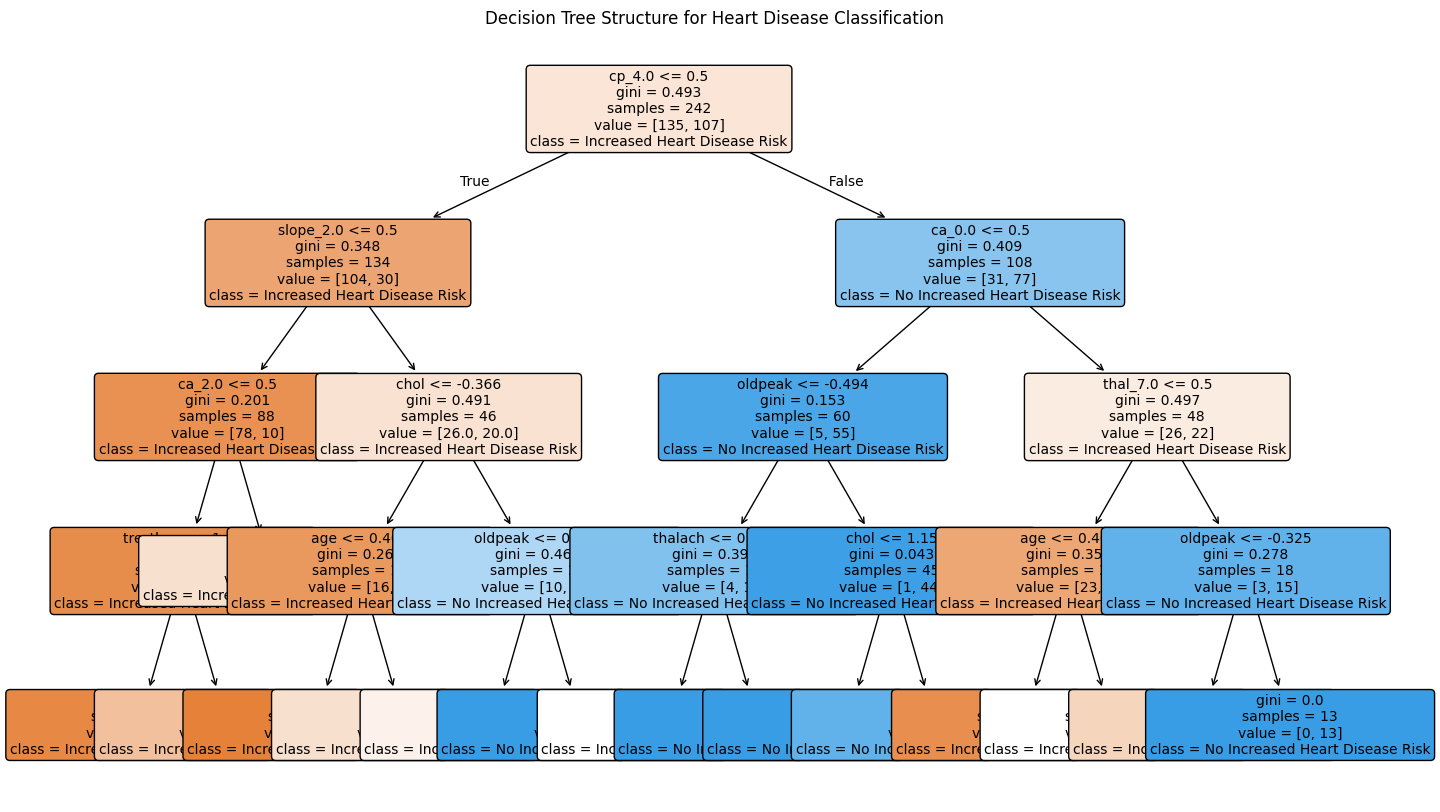

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

numeric_features = [
    'age','trestbps', 'chol', 'thalach', 'oldpeak'
]

# Extract feature names from the preprocessor step
cat_encoder = dtc.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot']
encoded_cat_features = cat_encoder.get_feature_names_out(categorical_features).tolist()

# Combine numerical and encoded categorical feature names
all_feature_names = numeric_features + encoded_cat_features

# Plot the trained decision tree
plt.figure(figsize=(16, 10))
plot_tree(
    dtc.named_steps["classifier"],
    #Troubleshooting feature names
    #https://stackoverflow.com/questions/66552426/how-to-display-feature-names-in-sklearn-decision-tree
    feature_names=all_feature_names,
    class_names=["Increased Heart Disease Risk", "No Increased Heart Disease Risk"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Structure for Heart Disease Classification")
plt.show()